# Desafío 1 - Procesamiento de Lenguaje Natural I
Vectorización TF-IDF, similaridad coseno y Naïve Bayes con 20 Newsgroups.

In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import f1_score

In [9]:
newsgroups_train = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
newsgroups_test = fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))
y_train = newsgroups_train.target
y_test = newsgroups_test.target
names = newsgroups_train.target_names

tfidfvect = TfidfVectorizer()
X_train = tfidfvect.fit_transform(newsgroups_train.data)
X_test = tfidfvect.transform(newsgroups_test.data)
print(X_train.shape, X_test.shape)

(11314, 101631) (7532, 101631)


## 1. Similaridad entre documentos
Se toman 5 documentos al azar y se listan los 5 más similares (similaridad coseno) con su clase.

In [10]:
# Semilla para el generador seudoaleatorio
np.random.seed(42)
# Vector de 5 numeros seudoaleatorios para la elección "al azar" de los documentos
rand_idx = np.random.choice(X_train.shape[0], 5, replace=False)

# Palabras con mayor peso TF-IDF de un documento
idx2word = {v: k for k, v in tfidfvect.vocabulary_.items()}

def top_terms(i, n=8):
    row = X_train[i]
    return [idx2word[j] for j in row.indices[np.argsort(row.data)[::-1][:n]]]

# Loop de documentos seleccionados aleatoriamente
for idx in rand_idx:
    # Similitudes coseno del documento elegido contra todos los de train (el índice es la posición)
    cossim = cosine_similarity(X_train[idx], X_train)[0]

    # Índices de los 5 documentos más similares
    cinco_mas_similares_idx = np.argsort(cossim)[::-1][1:6]

    print('\n')
    print(f'INDICE {idx} - clase: {names[y_train[idx]]} - clave: {top_terms(idx)}')
    print(newsgroups_train.data[idx].replace('\n', ' '))

    for i in cinco_mas_similares_idx:
        print(f'  -> {i} - sim={cossim[i]:.3f} - {names[y_train[i]]} - clave: {top_terms(i)}')
        print('     ', newsgroups_train.data[i].replace('\n', ' '))



INDICE 7492 - clase: comp.sys.mac.hardware - clave: ['rrn', 'novitskey', 'banging', 'cwru', 'pursuing', 'reward', 'po', 'opportunity']
Could someone please post any info on these systems.  Thanks. BoB --  ----------------------------------------------------------------------  Robert Novitskey | "Pursuing women is similar to banging one's head rrn@po.cwru.edu  |  against a wall...with less opportunity for reward" 
  -> 10935 - sim=0.667 - comp.sys.mac.hardware - clave: ['rrn', 'cwru', 'po', 'want', 'areound', 'novitskey', 'price', 'buy']
      Hey everybody:     I want to buy a mac and I want to get a good price...who doesn't?  So, could anyone out there who has found a really good deal on a Centris 650 send me the price.  I don't want to know where, unless it is mail order or areound cleveland, Ohio.  Also, should I buy now or wait for the Power PC.  Thanks. BoB reply via post or e-mail at rrn@po.cwru.edu --  ----------------------------------------------------------------------  Rob

| Doc original | Clase original | Vecino | Clase vecino | Sim. | Misma clase | Comentario |
|---|---|---|---|---|---|---|
| 7492 | comp.sys.mac.hardware | 10935 | comp.sys.mac.hardware | 0.667 | Sí | Similitud coseno alta por ser un mail de la misma casilla. Contiene la palabra "mac" lo cual probablemente puede pesar en la clasificaicón|
| 7492 | comp.sys.mac.hardware | 7258 | comp.sys.ibm.pc.hardware | 0.348 | No | La similitud coseno da ralativamente alta porque ambos textos son mails de la misma persona, pero es clasificado como ibm.pc dado que menciona nombres de pc p24v, 486/66  |
| 7492 | comp.sys.mac.hardware | 4971 | comp.sys.mac.hardware | 0.180 | Sí | Igual al anterior, son mails del mismo dominio. Este captura la clase mac por palabras como simms y vram |
| 7492 | comp.sys.mac.hardware | 4303 | misc.forsale | 0.155 | No | Similitud coseno por ser mails del mismo dominio, pero corresponde a otra clase |
| 7492 | comp.sys.mac.hardware | 645 | comp.sys.mac.hardware | 0.141 | Sí | Habla de procesadores 68040/68060 que son mac y palabras muy específicas |
| 3546 | comp.os.ms-windows.misc | 5665 | comp.sys.ibm.pc.hardware | 0.204 | No | Ambos tienen la palabra "dma" y lenguaje técnico de computacion pero claramente de clases distintas, aunque cercanas |
| 3546 | comp.os.ms-windows.misc | 2011 | comp.sys.ibm.pc.hardware | 0.192 | No | Ambas tienen las palabras "dma" y "no". Mas allá de eso las clases son similares |
| 3546 | comp.os.ms-windows.misc | 8643 | comp.sys.ibm.pc.hardware | 0.172 | No | Ambas tienen las palabras "dma", dominions similares |
| 3546 | comp.os.ms-windows.misc | 1546 | comp.sys.ibm.pc.hardware | 0.171 | No | Ambas tienen las palabras "scsi" "tape" que son IT y fácilmente se pueden encontrar en ambas clases |
| 3546 | comp.os.ms-windows.misc | 8765 | comp.sys.ibm.pc.hardware | 0.162 | No | Ambas tienen las palabras "dma", dominions similares. |
| 5582 | misc.forsale | 5510 | misc.forsale | 0.462 | Sí | Comparten palabras clave en la firma por ser mensajes del mismo autor, pero no relacionadas con la clase. |
| 5582 | misc.forsale | 4922 | misc.forsale | 0.300 | Sí | Igual que el anterior. |
| 5582 | misc.forsale | 4347 | comp.graphics | 0.274 | No | Igual que los anteriores, en este caso en una clase distinta. La similitud viene dada por las palabras en la firma. |
| 5582 | misc.forsale | 8057 | misc.forsale | 0.208 | Sí | Comparten palabras técnicas de hardware de IT pero que no necesariamente están relacionadas con la clase. |
| 5582 | misc.forsale | 4028 | comp.graphics | 0.169 | No | Posiblemente la similitud coseno venga dada por compartir "monochrome". Este caso es opuesto a los anteriores en los que compartían palabras técnicas de IT y pertenecían a la misma clase (no necesariamente asociada a las palabras que contribuyen a la similitud coseno). |
| 4793 | talk.politics.guns | 6894 | talk.politics.guns | 0.236 | Sí | El valor de simulitud coseno parece estar dado por la palabra "national" y artículos así como otras palabras irrelevantes a la clasificación. El segmento 4028 es un press release de la casa blanca, con lo que es un texto muy largo con muchas palabras. |
| 4793 | talk.politics.guns | 5856 | sci.crypt | 0.236 | No | Coinciden solo palabras que no hacen a la clasificación. |
| 4793 | talk.politics.guns | 4271 | talk.politics.misc | 0.233 | No | Igual que la anterior. La clase es similar. |
| 4793 | talk.politics.guns | 3141 | talk.politics.guns | 0.230 | Sí | Ambos contienen "gun" y "guns" así como muchos artículos. |
| 4793 | talk.politics.guns | 10836 | alt.atheism | 0.229 | No | Coinciden solo palabras que no hacen a la clasificación. |
| 3813 | rec.sport.hockey | 10836 | alt.atheism | 0.251 | No | El documento de referencia 3813 está clasificado como hockey aunque el mensaje no parece contener nada relevante al hockey. La similitud parece venir de palabras irrelevantes a la clasificaión. |
| 3813 | rec.sport.hockey | 759 | soc.religion.christian | 0.248 | No | Igual al anterior. |
| 3813 | rec.sport.hockey | 913 | alt.atheism | 0.241 | No | Igual a los anteriores. |
| 3813 | rec.sport.hockey | 5826 | soc.religion.christian | 0.241 | No | Igual a los anteriores. |
| 3813 | rec.sport.hockey | 5856 | sci.crypt | 0.233 | No | Igual a los anteriores. |

La similitud coseno sobre TF-IDF sin ningún tipo de pre proceso o filtro puede dar similitudes altas entre textos de temas distintos por palabras irrelevantes (vacías, firmas, nombres). El método solo compara coincidencias léxicas y no el significado, con lo cual las dirección del vector asociado al documento no siempre está influenciado fuertemente por palabras relacionadas a la temática. Esto lleva a que documentos tengan algunos vecinos en los que el tema coincide y otros que no. Textos con poco contenido relacionado con la clase, como 3813, tienen vecinos que no coinciden para nada con la temática del documento de referencia.

## 2. Clasificador por prototipos (tipo zero-shot)
Cada documento de test recibe la clase del documento de train más similar según la similitud coseno entre los documentos.

In [11]:
# Matriz de similitudes entre todos los documentos de train y todos los de test. 
# Tantas filas como documentos de test y tantas columnas como documentos de train y los valores son las similaridades entre ese par.
sim = cosine_similarity(X_test, X_train)

# Para cada fila, o documento de test, encuentro la columna (índice del documento de train) con mayor similitud coseno
mayores_similitudes = np.argmax(sim, axis=1)

# Ahora me quedo con las etiquetas de los documentos de train indexados que daban mayor similitud coseno con los de test y éstas son 
# las predicciones del modelo
y_sombrero_zs = y_train[mayores_similitudes]

# Calcula el F1 de cada una de las 20 clases y luego promedia
f1_zs = f1_score(y_test, y_sombrero_zs, average='macro')
print('F1 macro 1-NN:', f1_zs)

F1 macro 1-NN: 0.5049911553681621


Este modelo no requiere entrenamiento pero es bastante rudimentario ya que tiene que comparar todo train contra todo test. Un baseline random con 20 clases daría cercano a 0.05 y el modelo logra 0.5, con lo que podemos decir que éste modelo "clasifica". Como se vió en el punto 1, usar la similitud coseno como métrica sin ningún tipo de filtro puede llegar a dar valores altos por palabras irrelevantes al contenido ya que no se captura el significado sinó coincidencias léixcas con lo que es de esperar que el desem,peño de f1 macro = 0.5 se pueda mejorar bastante con modelos mas adecuados.

## 3. Naive Bayes: maximizar F1 macro
Se varían vectorizador (TF-IDF / Count), `stop_words`, `min_df`, `max_df`, `sublinear_tf`, modelo (Multinomial / Complement) y `alpha`. No se modifica `ngram_range`.

Primero una idea de distribución de clases.

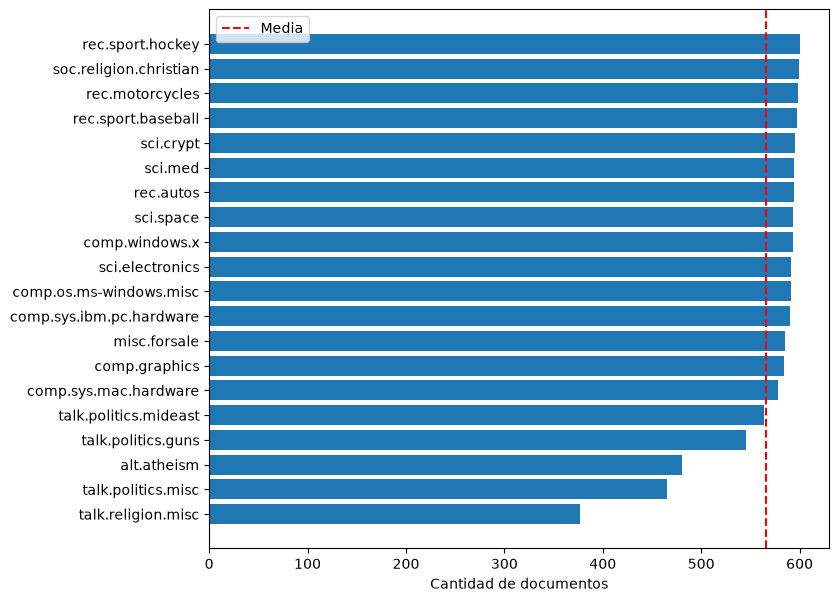

In [12]:
import matplotlib.pyplot as plt

conteos = np.bincount(y_train)
orden = np.argsort(conteos)
plt.figure(figsize=(8, 7))
plt.barh(np.array(names)[orden], conteos[orden])
plt.axvline(conteos.mean(), color='red', linestyle='--', label='Media')
plt.xlabel('Cantidad de documentos')
plt.legend()
plt.show()

Hay desbalance de clases leve. Ateísmo, política y religión son las mas desfavorecidas en cantidad de documentos (y a su véz posiblemente cercanas en temática). La métrica f1_macro ayuda cuando hay desbalance de clases.

In [13]:
from sklearn.model_selection import train_test_split

# Separa una parte de train como validación (estratificada para mantener la proporción de clases) ya que hay que elegir hiperparámetros 
# y comparar distintos modelos
idx_tr, idx_val = train_test_split(
    np.arange(len(y_train)), test_size=0.2, stratify=y_train, random_state=42
)
textos_train = [newsgroups_train.data[i] for i in idx_tr]
textos_validacion = [newsgroups_train.data[i] for i in idx_val]
y_tr, y_val = y_train[idx_tr], y_train[idx_val]

# Parámetros de vectorización
param_vectorizado = [
    # Parámetros default
    dict(),
    # Eliminando stop words en inglés
    dict(stop_words='english'),
    # Eliminando stop words en inglés y considerando solo términos que aparecen al menos 2 veces
    dict(stop_words='english', min_df=2),
    # Eliminando stop words en inglés, considerando solo términos que aparecen al menos 2 veces y como máximo en la mitad de los documentos
    dict(stop_words='english', min_df=2, max_df=0.5),
    # Eliminando stop words en inglés, considerando solo términos que aparecen al menos 2 veces y penalizando menos las repeticiones
    dict(stop_words='english', min_df=2, sublinear_tf=True),
]

rows = []

# Itera sobre cada conjunto de parámetros de vectorización
for vp in param_vectorizado:
    # Itera sobre cada tipo de vectorizador (TF-IDF y Count)
    for Vec in (TfidfVectorizer, CountVectorizer):
        # No se puede usar sublinear_tf con CountVectorizer
        p = {k: v for k, v in vp.items() if not (Vec is CountVectorizer and k == 'sublinear_tf')}
        # Crea el vectorizador con los parámetros filtrados
        vec = Vec(**p)
        # Ajusta el vectorizador solo con el subconjunto de entrenamiento y transforma train y validación
        Xtr = vec.fit_transform(textos_train)
        Xval = vec.transform(textos_validacion)
        # Itera sobre cada modelo y cada valor de alfa
        for modelo in (MultinomialNB, ComplementNB):
            for alfa in (0.01, 0.03, 0.1, 0.3, 1.0):
                m = modelo(alpha=alfa).fit(Xtr, y_tr)
                f1 = f1_score(y_val, m.predict(Xval), average='macro')
                rows.append(dict(f1_macro_val=f1, vectorizer=Vec.__name__, params=p, model=modelo.__name__, alpha=alfa))

# Resultados ordenados por F1 macro en validación (descendente)
res = pd.DataFrame(rows).sort_values('f1_macro_val', ascending=False).reset_index(drop=True)
res['params'] = res['params'].astype(str)
display(res.head(15))

# Reentrena la mejor combinación con todo train y mide UNA sola vez en test
mejor = res.iloc[0]
vec_final = {'TfidfVectorizer': TfidfVectorizer, 'CountVectorizer': CountVectorizer}[mejor.vectorizer](**eval(mejor.params))
modelo_final = {'MultinomialNB': MultinomialNB, 'ComplementNB': ComplementNB}[mejor.model](alpha=mejor.alpha)
modelo_final.fit(vec_final.fit_transform(newsgroups_train.data), y_train)
y_pred_final = modelo_final.predict(vec_final.transform(newsgroups_test.data))

print('Mejor configuración (validación):', mejor.to_dict())
print('F1 macro en validación:', mejor.f1_macro_val)
print('F1 macro en test:', f1_score(y_test, y_pred_final, average='macro'))

,f1_macro_val,vectorizer,params,model,alpha
0,0.774194,TfidfVectorizer,{'stop_words': 'english'},ComplementNB,0.30
1,0.774188,TfidfVectorizer,{'stop_words': 'english'},ComplementNB,0.10
2,0.771207,TfidfVectorizer,{},ComplementNB,0.10
3,0.770913,TfidfVectorizer,{},ComplementNB,0.30
4,0.765681,TfidfVectorizer,{'stop_words': 'english'},ComplementNB,0.03
5,0.764488,TfidfVectorizer,{},ComplementNB,0.03
6,0.762649,TfidfVectorizer,"{'stop_words': 'english', 'min_df': 2, 'max_df...",ComplementNB,0.10
7,0.762649,TfidfVectorizer,"{'stop_words': 'english', 'min_df': 2}",ComplementNB,0.10
8,0.762564,TfidfVectorizer,"{'stop_words': 'english', 'min_df': 2, 'max_df...",ComplementNB,0.30
9,0.762564,TfidfVectorizer,"{'stop_words': 'english', 'min_df': 2}",ComplementNB,0.30


Mejor configuración (validación): {'f1_macro_val': 0.7741943977914569, 'vectorizer': 'TfidfVectorizer', 'params': "{'stop_words': 'english'}", 'model': 'ComplementNB', 'alpha': 0.3}
F1 macro en validación: 0.7741943977914569
F1 macro en test: 0.6993120842271471


In [14]:
print('Mejor MultinomialNB:\n', res[res.model == 'MultinomialNB'].iloc[0].to_dict())
print('Mejor ComplementNB:\n', res[res.model == 'ComplementNB'].iloc[0].to_dict())

Mejor MultinomialNB:
 {'f1_macro_val': 0.7591168994403077, 'vectorizer': 'TfidfVectorizer', 'params': '{}', 'model': 'MultinomialNB', 'alpha': 0.01}
Mejor ComplementNB:
 {'f1_macro_val': 0.7741943977914569, 'vectorizer': 'TfidfVectorizer', 'params': "{'stop_words': 'english'}", 'model': 'ComplementNB', 'alpha': 0.3}


| Modelo | Vectorizador | Parámetros del vectorizador | `alpha` | F1 macro (validación) | F1 macro (test) | Mejora vs. base (0.585) |
|---|---|---|---|---|---|---|
| MultinomialNB (base) | TfidfVectorizer | default | 1.0 | — | 0.585 | — |
| MultinomialNB (mejor, elegido sobre test) | TfidfVectorizer | `stop_words='english'` | 0.01 | — | 0.684 | +0.099 |
| ComplementNB (mejor, elegido sobre test) | TfidfVectorizer | default | 0.3 | — | 0.700 | +0.115 |
| ComplementNB (mejor, elegido sobre validación) | TfidfVectorizer | `stop_words='english'` | 0.3 | 0.774 | 0.699 | +0.114 |

Naive Bayes supera ampliamente al clasificador por prototipos.

Los 10 mejores resultados se obtuvieron con el algoritmo ComplementNB. Considerando la mejor configuración de cada algoritmo, ComplementNB supera a MultinomialNB por ~0.015. Esto puede deberse al leve desbalance de clases observado, porque ComplementNB estima los parámetros de cada clase con los datos de las demás, lo que beneficia a las clases chicas. MultinomialNB funciona mejor cuando se eliminan palabras vacías y se usa un alfa muy bajo, mientras que ComplementNB es más robusto a las palabras frecuentes.

Al elegir los hiperparámetros con un conjunto de validación (20% de train), ComplementNB también resultó el mejor modelo (F1 validación 0.774) y obtuvo 0.699 en test, prácticamente igual al 0.700 obtenido eligiendo directamente sobre test. La diferencia entre los scores sobre validación y test se debe a que los documentos de train y test cubren distintos períodos de tiempo, con lo cual es esperable que el vocabulario y la forma en que se usa haya cambiado levemente entre los documentos de uno y otro.

Por último vemos el ranking de clases en las que los modelos se equivocan.

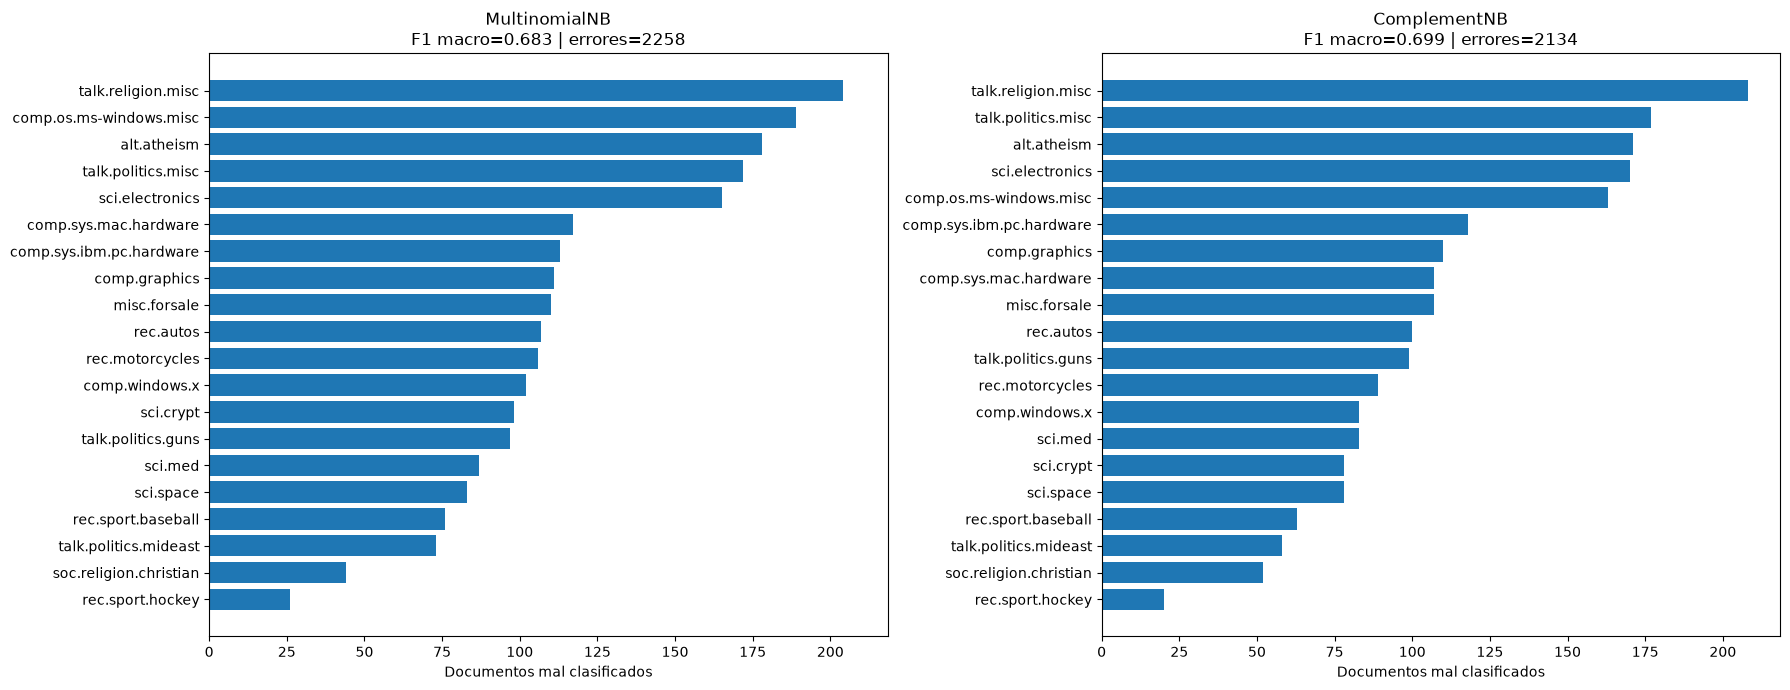

In [15]:
import matplotlib.pyplot as plt

# Mejor de cada modelo según validación, reentrenado con todo train
def entrenar_mejor(nombre_modelo):
    fila = res[res.model == nombre_modelo].iloc[0]
    Vec = {'TfidfVectorizer': TfidfVectorizer, 'CountVectorizer': CountVectorizer}[fila.vectorizer]
    Mod = {'MultinomialNB': MultinomialNB, 'ComplementNB': ComplementNB}[nombre_modelo]
    vec_m = Vec(**eval(fila.params))
    m = Mod(alpha=fila.alpha).fit(vec_m.fit_transform(newsgroups_train.data), y_train)
    return m.predict(vec_m.transform(newsgroups_test.data))

predicciones = {
    'MultinomialNB': entrenar_mejor('MultinomialNB'),
    'ComplementNB': entrenar_mejor('ComplementNB'),
}

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True)
for ax, (titulo, y_pred) in zip(axes, predicciones.items()):
    errores = np.where(y_pred != y_test)[0]
    por_clase = np.bincount(y_test[errores], minlength=20)
    orden = np.argsort(por_clase)
    ax.barh(np.array(names)[orden], por_clase[orden])
    f1 = f1_score(y_test, y_pred, average='macro')
    ax.set_title(f'{titulo}\nF1 macro={f1:.3f} | errores={len(errores)}')
    ax.set_xlabel('Documentos mal clasificados')
plt.tight_layout()
plt.show()

* Ambos modelos se equivocan en las clases con menos ejemplos. En el caso de religión, política y ateísmo, son temas que además están relacionados lo cual puede influir en los errores en la inferencia.
* ComplementNB mejora bastante el desempeño en windows.misc. No se me ocurre por qué ya que no es un tema de clase desfavorecida en cantidad de ejemplos.
* Ambos tienen desempeño pobre en sci.electronics que tiene muchos ejemplos. Posiblemente por utilizar palabras muy comunes en otros temas como los relacionados con IT.
* El top 5 de clases con mejor desempeño es común a ambos modelos. Es posible que esto se deba a que son temas con vocabulario muy particular que produzcan documentos con vectores bastante alineados.

## 4. Similaridad entre palabras (matriz término-documento)
Se transpone la matriz documento-término; cada fila es el vector de una palabra. Palabras elegidas manualmente.

In [16]:
vec = TfidfVectorizer(stop_words='english', min_df=5)
Xtr = vec.fit_transform(newsgroups_train.data)
X_terms = Xtr.T.tocsr()
w2i = vec.vocabulary_
i2w = {v: k for k, v in w2i.items()}

palabras = ['atheist', 'scsi', 'intelligence', 'install', 'gun']
for w in palabras:
    s = cosine_similarity(X_terms[w2i[w]], X_terms)[0]
    top = np.argsort(s)[::-1][1:6]
    print(f'{w:10s}', [(i2w[i], round(float(s[i]), 3)) for i in top])

atheist    [('atheism', 0.325), ('anarchal', 0.311), ('atheists', 0.292), ('techno', 0.286), ('doubtless', 0.283)]
scsi       [('asynchronous', 0.478), ('6mb', 0.388), ('10mb', 0.373), ('synchronous', 0.347), ('ide', 0.309)]
intelligence [('comeback', 0.293), ('wit', 0.275), ('lax', 0.195), ('continues', 0.182), ('grunt', 0.182)]
install    [('reinstall', 0.199), ('344', 0.194), ('dll', 0.134), ('caddy', 0.132), ('floppies', 0.128)]
gun        [('guns', 0.375), ('handgun', 0.245), ('crime', 0.243), ('firearms', 0.238), ('homicides', 0.231)]


| Palabra | Similar 1 | Similar 2 | Similar 3 | Similar 4 | Similar 5 | Comentario |
|---|---|---|---|---|---|---|
| atheist | atheism (0.325) | anarchal (0.311) | atheists (0.292) | techno (0.286) | doubtless (0.283) | `atheism` y `atheists` son variantes morfológicas y tienen sentido. `anarchal` y `techno` aparecen por la firma de un autor (ya vista en el punto 1), no por significado. 3 vecinos relacionados, 2 sin relación. |
| scsi | asynchronous (0.478) | 6mb (0.388) | 10mb (0.373) | synchronous (0.347) | ide (0.309) | Todos son términos técnicos de IT. Los 5 vecinos están relacionados por temática. |
| intelligence | comeback (0.293) | wit (0.275) | lax (0.195) | continues (0.182) | grunt (0.182) | No hay vecinos con similitud muy alta. La palabra no tiene lazos muy fuertes con ninguna de las temáticas de los documentos y probablemente aparece esporádicamente en documentos poco relacionados. 5 vecinos sin relaciópn. |
| install | reinstall (0.199) | 344 (0.194) | dll (0.134) | caddy (0.132) | floppies (0.128) | `reinstall`, `dll` y `floppies` son términos relacionados con IT. `344` y `caddy` no tienen relación y obtuvieron similitudes muy bajas. 3 vecinos relacionados (y muy cercanos) y 2 no relacionados. |
| gun | guns (0.375) | handgun (0.245) | crime (0.243) | firearms (0.238) | homicides (0.231) | Plural de la misma palabra, sinónimos (`firearms`, `handgun`) y temas asociados (`crime`, `homicides`) del tema de armas. 5 vecinos relacionados. |

La similitud coseno crece cuando los ángulos de los vectores a los que se codifican las palabras son similares. En éste caso, eso se traduce a un valor alto de similitud coseno cuando las palabras aparecen en los mismos documentos, no cuando significan lo mismo. Por eso se observan similitudes altas cuando dos palabras sin ninguna relación en su significado ("atheist" y "techno") aparecen en la firma de un mail lo cual lleva a que se encuentren juntas en un mismo documento. Si además son palabras poco frecuentes, el IDF les da peso.

Por otro lado, hay casos en los cuales los vecinos sí son palabras muy relacionadas a la de referencia en significado y temática como por ejemplo los vecinos de "guns".

# Anexo

Interpretación del puntaje TF-IDF previo a la normalización en el documento.

* Si el vectorizado se aplica sobre el conjunto de train (11314 documentos):
    * df = 50: palabra específica de un tema.
    * df = 1000: palabra regular del vocabulario, que puede aparecer en documentos de diversos temas.
    * df = 5000: palabra muy común (artículos, preposiciones) que no se asocia a ningún tema.

* sublinear_tf no se usó en el modelo ganador. Se probó en una de las configuraciones del grid search sin mejoras, y se grafica aquí para entender su efecto.

* A grandes rasgos, una palabra específica que aparece 2 veces en un documento tiene un score similar a una palabra regular que aparece 4 veces, o a una palabra muy común que aparece 8 veces.

* Esto explica cómo las palabras muy frecuentes pueden pesar bastante en la vectorización y generar "ruido" al comparar documentos por temática con TF-IDF, como se vio en el punto 1. Eliminar stop words mitiga el problema.

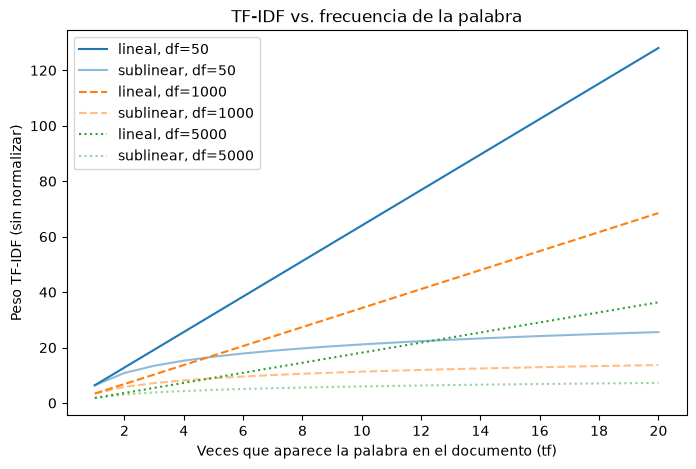

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

n = 11314                      # documentos en train
tf = np.arange(1, 21)          # veces que aparece la palabra en un documento

plt.figure(figsize=(8, 5))
for df, estilo in [(50, '-'), (1000, '--'), (5000, ':')]:
    idf = np.log((1 + n) / (1 + df)) + 1
    plt.plot(tf, tf * idf, estilo, label=f'lineal, df={df}')
    plt.plot(tf, (1 + np.log(tf)) * idf, estilo, color=plt.gca().lines[-1].get_color(),
             alpha=0.5, label=f'sublinear, df={df}')

plt.xlabel('Veces que aparece la palabra en el documento (tf)')
plt.ylabel('Peso TF-IDF (sin normalizar)')
plt.title('TF-IDF vs. frecuencia de la palabra')
plt.xticks(tf[1::2])
plt.legend()
plt.show()